*******PIZZA SALES DATA ANALYSIS PROJECT*******

In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 

In [3]:
df=pd.read_csv("C:/Users/NCS B1/Desktop/pizza_sales.csv")

In [4]:
df.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,01-01-2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,01-01-2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,01-01-2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,01-01-2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,01-01-2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  str    
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  str    
 5   order_time         48620 non-null  str    
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  str    
 9   pizza_category     48620 non-null  str    
 10  pizza_ingredients  48620 non-null  str    
 11  pizza_name         48620 non-null  str    
dtypes: float64(2), int64(3), str(7)
memory usage: 10.4 MB


In [6]:
df.isnull().sum()

pizza_id             0
order_id             0
pizza_name_id        0
quantity             0
order_date           0
order_time           0
unit_price           0
total_price          0
pizza_size           0
pizza_category       0
pizza_ingredients    0
pizza_name           0
dtype: int64

In [7]:
print(df.duplicated().sum())

0


In [8]:
#Convert the column name in a best format and replace the under score by space
df.columns=df.columns.str.lower()
df.columns=df.columns.str.replace("_"," ")


In [9]:
df.columns

Index(['pizza id', 'order id', 'pizza name id', 'quantity', 'order date',
       'order time', 'unit price', 'total price', 'pizza size',
       'pizza category', 'pizza ingredients', 'pizza name'],
      dtype='str')

In [10]:
#convert the data type of order date from str to datetime
df['order date']=pd.to_datetime(df['order date'],dayfirst=True)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   pizza id           48620 non-null  int64         
 1   order id           48620 non-null  int64         
 2   pizza name id      48620 non-null  str           
 3   quantity           48620 non-null  int64         
 4   order date         48620 non-null  datetime64[us]
 5   order time         48620 non-null  str           
 6   unit price         48620 non-null  float64       
 7   total price        48620 non-null  float64       
 8   pizza size         48620 non-null  str           
 9   pizza category     48620 non-null  str           
 10  pizza ingredients  48620 non-null  str           
 11  pizza name         48620 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(3), str(6)
memory usage: 10.0 MB


In [12]:
df.head()

,pizza id,order id,pizza name id,quantity,order date,order time,unit price,total price,pizza size,pizza category,pizza ingredients,pizza name
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [13]:
#Drop unusable column
cols=df[['order time','pizza ingredients']]
df.drop(cols,axis=1,inplace=True)

In [14]:
df.head()

,pizza id,order id,pizza name id,quantity,order date,unit price,total price,pizza size,pizza category,pizza name
0,1,1,hawaiian_m,1,2015-01-01,13.25,13.25,M,Classic,The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01,16.00,16.00,M,Classic,The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01,18.50,18.50,L,Veggie,The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01,20.75,20.75,L,Supreme,The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01,16.00,16.00,M,Veggie,The Mexicana Pizza


In [15]:
#Add month and day column
df['month']=df['order date'].dt.month_name().str[:3]
df['day']=df['order date'].dt.day_name().str[:3]

In [16]:
df.describe()

,pizza id,order id,quantity,order date,unit price,total price
count,48620.000000,48620.000000,48620.000000,48620,48620.000000,48620.000000
mean,24310.500000,10701.479761,1.019622,2015-06-29 11:03:43.611682,16.494132,16.821474
min,1.000000,1.000000,1.000000,2015-01-01 00:00:00,9.750000,9.750000
25%,12155.750000,5337.000000,1.000000,2015-03-31 00:00:00,12.750000,12.750000
50%,24310.500000,10682.500000,1.000000,2015-06-28 00:00:00,16.500000,16.500000
75%,36465.250000,16100.000000,1.000000,2015-09-28 00:00:00,20.250000,20.500000
max,48620.000000,21350.000000,4.000000,2015-12-31 00:00:00,35.950000,83.000000
std,14035.529381,6180.119770,0.143077,NaN,3.621789,4.437398


In [17]:
df.head()

,pizza id,order id,pizza name id,quantity,order date,unit price,total price,pizza size,pizza category,pizza name,month,day
0,1,1,hawaiian_m,1,2015-01-01,13.25,13.25,M,Classic,The Hawaiian Pizza,Jan,Thu
1,2,2,classic_dlx_m,1,2015-01-01,16.00,16.00,M,Classic,The Classic Deluxe Pizza,Jan,Thu
2,3,2,five_cheese_l,1,2015-01-01,18.50,18.50,L,Veggie,The Five Cheese Pizza,Jan,Thu
3,4,2,ital_supr_l,1,2015-01-01,20.75,20.75,L,Supreme,The Italian Supreme Pizza,Jan,Thu
4,5,2,mexicana_m,1,2015-01-01,16.00,16.00,M,Veggie,The Mexicana Pizza,Jan,Thu


KPIS

In [18]:
#total revenue
print(f'the total revenue is{df['total price'].sum().round(2)}')

the total revenue is817860.05


In [19]:
#Total quantity sold
print(f"the total quantity is sold {df['quantity'].sum().round(2)} ")

the total quantity is sold 49574 


In [20]:
#Total orders
print(f"the total orders is {df['order id'].nunique()}")

the total orders is 21350


In [21]:
#Average order value
print(f"the average order value is {(df['total price'].sum()/df['order id'].nunique()).round(2)}")

the average order value is 38.31


In [22]:
#Average quantity per order
print(f"the average quantity per order is {(df['quantity'].sum()/df['order id'].nunique()).round(2)}")

the average quantity per order is 2.32


In [23]:
#Average unit price
print(f"the average unit price is {df['unit price'].mean().round(2)}")

the average unit price is 16.49


In [24]:
#Highest single order value
print(f"highest single order value is {df.groupby("order id")['total price'].sum().max()}")

highest single order value is 444.2


In [25]:
#Lowest single order value
print(f"the lowest single order value is {df.groupby("order id")['total price'].sum().min()}")

the lowest single order value is 9.75


In [26]:
#Top orders by value
print(f" {df.groupby("order id")['total price'].sum().sort_values(ascending=False).head(5)}")

 order id
18845    444.20
10760    417.15
1096     285.15
6169     284.00
740      280.95
Name: total price, dtype: float64


C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\418510731.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(x=df['day'],y=df['order id'],estimator=lambda x:len(set(x)),data=df,palette='viridis',hue=None)


([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'Thu'),
  Text(1, 0, 'Fri'),
  Text(2, 0, 'Sat'),
  Text(3, 0, 'Sun'),
  Text(4, 0, 'Mon'),
  Text(5, 0, 'Tue'),
  Text(6, 0, 'Wed')])

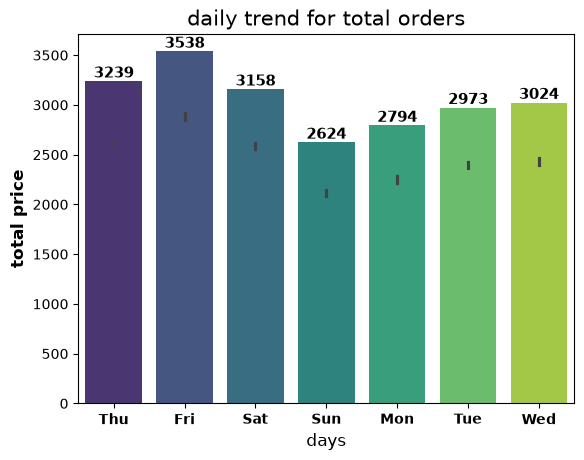

In [27]:
#Daily trend for total orders
plt.Figure(figsize=(10,5))
ax=sns.barplot(x=df['day'],y=df['order id'],estimator=lambda x:len(set(x)),data=df,palette='viridis',hue=None)
for container in ax.containers:
    ax.bar_label(container,fontweight='bold',fontsize=11)
plt.title("daily trend for total orders",fontsize=15,color='black')
plt.xlabel("days",fontsize=12,color='black')
plt.ylabel("total price",fontsize=12,weight='bold')
plt.xticks(weight="bold")

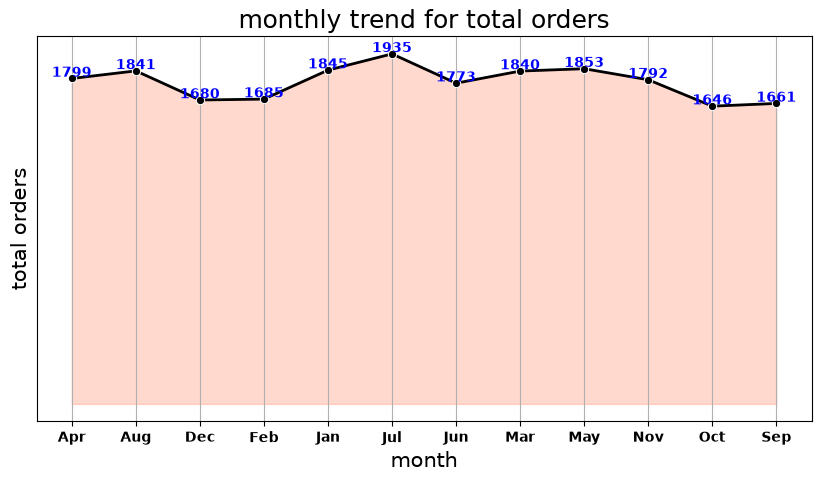

In [28]:
#monthly trend for total orders
plt.figure(figsize=(10,5))
df.columns=df.columns.str.strip()
monthly_order=df.groupby("month")['order id'].nunique().reset_index()
ax=sns.lineplot(x='month',y='order id',data=monthly_order,color="black",linewidth=2,marker='o')
plt.fill_between(monthly_order['month'],monthly_order['order id'],alpha=0.3,color='#ff7e5f')
for i in range(len(monthly_order)):
    plt.text(
        x=monthly_order['month'].iloc[i],
        y=monthly_order['order id'].iloc[i]+10,
        s=str(monthly_order['order id'].iloc[i]),
        ha='center',
        fontsize=10,fontweight='bold',color='blue'
    )
plt.title("monthly trend for total orders",fontsize=18)
plt.xlabel('month',fontsize='15')
plt.ylabel("total orders",fontsize=15)
plt.xticks(weight="bold")
plt.yticks([])
plt.grid()

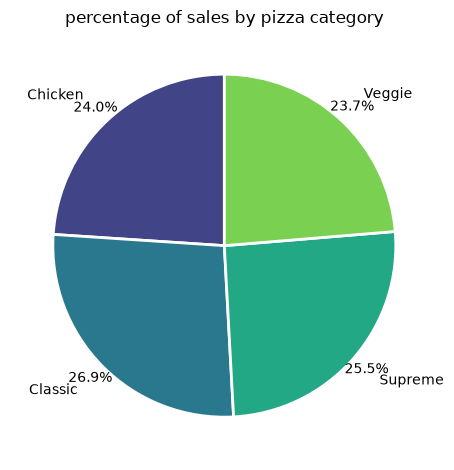

In [29]:
#percentage of sales by pizza category
plt.Figure(figsize=(10,5))
sales_by_category=df.groupby("pizza category")['total price'].sum()
plt.pie(sales_by_category.values,labels=sales_by_category.index,autopct='%1.1f%%',wedgeprops={"edgecolor":"white",'linewidth':2},pctdistance=1.1,
        startangle=90,labeldistance=1.2,colors=sns.color_palette("viridis",len(sales_by_category)))
plt.title("percentage of sales by pizza category")
plt.tight_layout()

Text(0.5, 1.0, 'percentage of sales by pizza size')

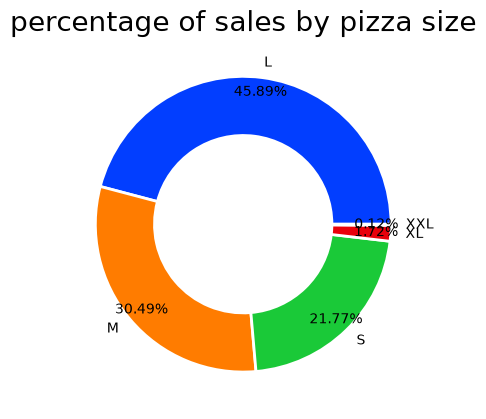

In [30]:
#percentage of sale by pizza size
sales=df.groupby("pizza size")['total price'].sum()
plt.Figure(figsize=(10,5))
auto=plt.pie(sales.values,labels=sales.index,autopct="%1.2f%%",pctdistance=0.9,wedgeprops={"width":0.4,"edgecolor":"white","linewidth":2},
        colors=sns.color_palette("bright",len(sales)))
plt.title("percentage of sales by pizza size",fontsize=20)

([], [])

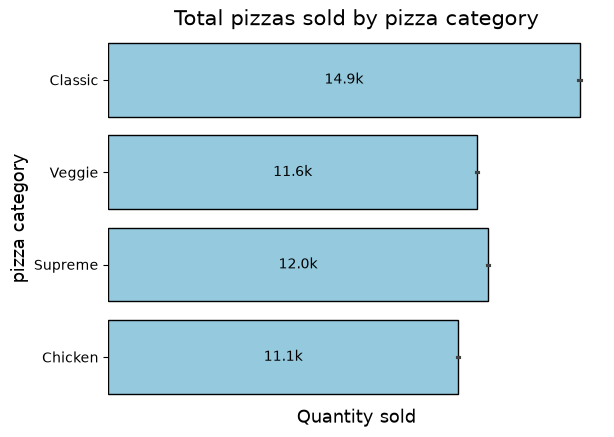

In [31]:
#TOTAL PIZZA SOLD BY PIZZA CATEGORY
plt.Figure(figsize=(10,5))
x=df['quantity']
y=df['pizza category']
ax=sns.barplot(x=x,y=y,data=df,estimator=sum,color="skyblue",edgecolor="black")
def to_k(x):
    if x>=1000:
        return f'{x/1000:.1f}k'
    else:
        return str(x)
for container in ax.containers:
    labels=[to_k(v) for v in container.datavalues]
    ax.bar_label(container,labels=labels,label_type="center",fontsize=10,color='black')
for spine in ax.spines.values():
    spine.set_visible(False)
plt.title("Total pizzas sold by pizza category",fontsize=15)
plt.xlabel("Quantity sold",fontsize=13)
plt.ylabel("pizza category",fontsize='13')
plt.xticks([])

*******BEST AND WORT SELLER*******

C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\1100942418.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=top,x="pizza name",y='total price',edgecolor="black",palette=colors)


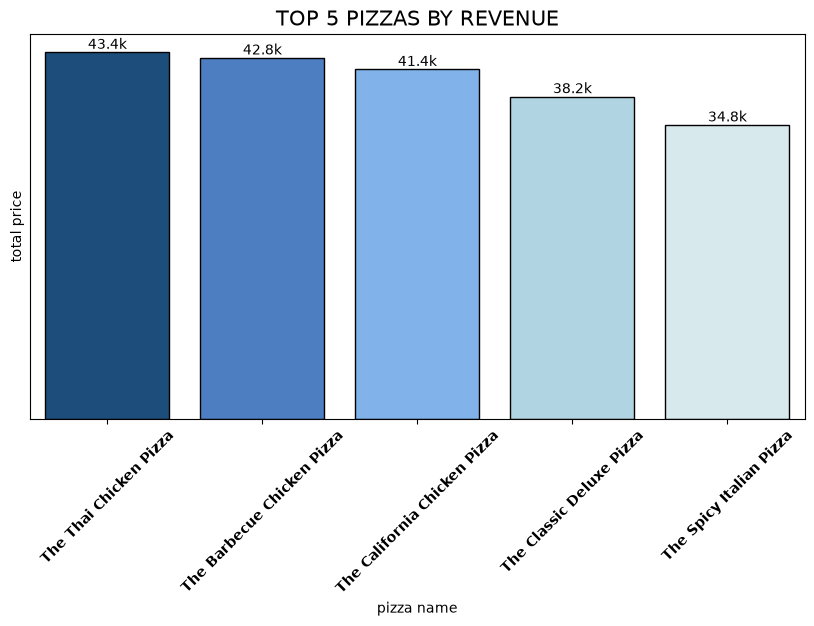

In [32]:
#TOP 5 pizzas by revenue
plt.figure(figsize=(10,5))
colors=['#0D4F8B','#3A7BD5','#6FB1FC','#A8D8EA','#D4EBF2']
top=df.groupby("pizza name")['total price'].sum().sort_values(ascending=False).nlargest(5).reset_index()
ax=sns.barplot(data=top,x="pizza name",y='total price',edgecolor="black",palette=colors)
plt.xticks(rotation=45,weight="bold")
plt.yticks([])
def to_k(x):
    if x>=1000:
        return f'{x/1000:.1f}k'
    else:
        return str(x)
for container in ax.containers:
    labels=[to_k(v) for v in container.datavalues]
    ax.bar_label(container,labels=labels,label_type="edge",fontsize=10,color='black')
plt.title("TOP 5 PIZZAS BY REVENUE",fontsize=15)
plt.xlabel("pizza name",fontsize=10)
plt.ylabel("total price",fontsize=10)
df.columns=df.columns.str.strip()



C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\1916251539.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=bottom,x='pizza name',y='total price',edgecolor='black',palette=color,width=0.5)


Text(0, 0.5, 'total price')

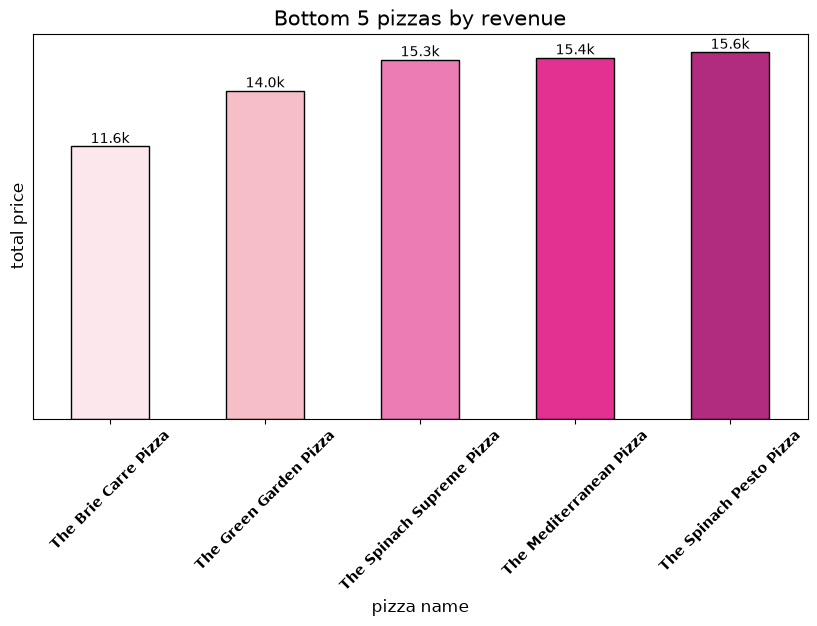

In [33]:
#BOTTOM 5 PIZZAS BY REVENUE
plt.figure(figsize=(10,5))
color=['#ffe4ec','#FFB6C1',"#FF69B4",'#FF1493','#C71585']
bottom=df.groupby("pizza name")['total price'].sum().sort_values(ascending=True).nsmallest(5).reset_index()
ax=sns.barplot(data=bottom,x='pizza name',y='total price',edgecolor='black',palette=color,width=0.5)
def to_k(x):
    if x>=1000:
        return f'{x/1000:.1f}k'
    else:
        return str(x)
for container in ax.containers:
    labels=[to_k(v) for v in container.datavalues]
    ax.bar_label(container,labels=labels,label_type="edge",fontsize=10,color='black')
plt.xticks(rotation=45,weight='bold')
plt.yticks([])
plt.title("Bottom 5 pizzas by revenue",fontsize=15)
plt.xlabel("pizza name",fontsize=12)
plt.ylabel("total price",fontsize=12)

C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\3121177715.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(x='pizza name',y='quantity',data=top,edgecolor='black',palette=color,width=0.7)


([], [])

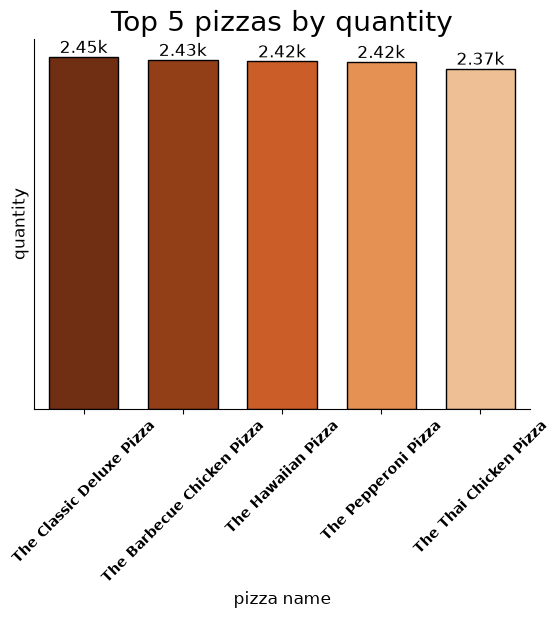

In [34]:
#TOP 5 PIZZAS BY QUANTITY
plt.Figure(figsize=(15,8))
color=['#7F2704','#A63603','#E6550D','#FD8D3C','#FDBE85']
top=df.groupby("pizza name")['quantity'].sum().sort_values(ascending=False).nlargest(5).reset_index()
ax=sns.barplot(x='pizza name',y='quantity',data=top,edgecolor='black',palette=color,width=0.7)
def in_k(val):
    if val>=1000:
        return f'{val/1000:.2f}k'
    else:
        return str(x)
for container in ax.containers:
    labels=[in_k(v) for v in container.datavalues] 
    ax.bar_label(container,labels=labels,label_type='edge',fontsize=12,color='black')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title("Top 5 pizzas by quantity",fontsize=20)
plt.xlabel("pizza name",fontsize=12)
plt.ylabel("quantity",fontsize=12)
plt.xticks(rotation=45,weight='bold')
plt.yticks([])

C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\3146027211.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(x='pizza name',y='quantity',data=bott,edgecolor='black',palette=colour)


([], [])

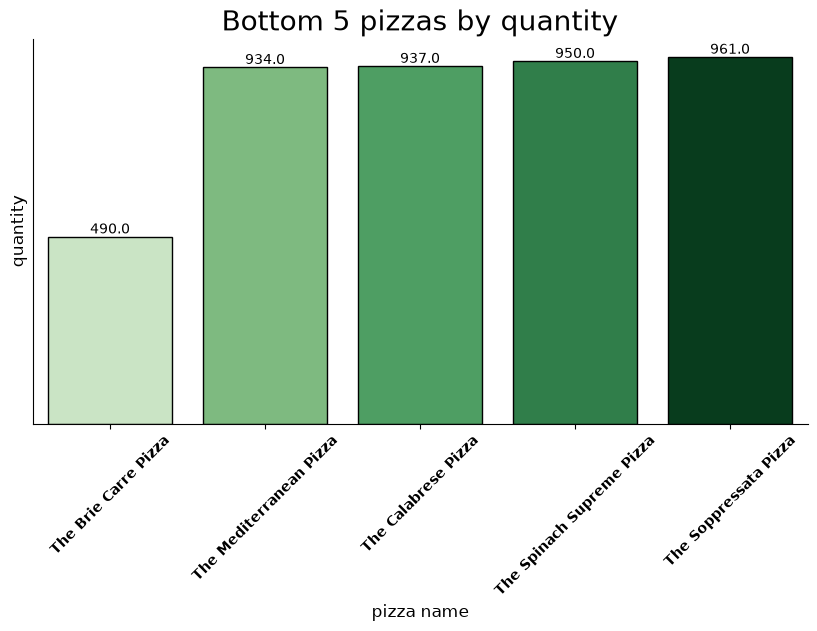

In [35]:
#BOOTTOM 5 PIZZAS BY QUANTITY
plt.figure(figsize=(10,5))
colour=['#c7e9c0','#74c476','#41ab5d','#238b45','#00441b']
bott=df.groupby("pizza name")['quantity'].sum().sort_values(ascending=True).nsmallest(5).reset_index()
ax=sns.barplot(x='pizza name',y='quantity',data=bott,edgecolor='black',palette=colour)
def to_k(val):
    if val>=1000:
        return f'{val/1000:.2f}k'
    else:
        return str(val)
for container in ax.containers:
    labels=[to_k(v) for v in container.datavalues]
    ax.bar_label(container,labels=labels,label_type='edge')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title("Bottom 5 pizzas by quantity",fontsize=20)
plt.xlabel("pizza name",fontsize=12)
plt.ylabel("quantity",fontsize=12)
plt.xticks(rotation=45,weight='bold')
plt.yticks([])

C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\4218586174.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(x='pizza name',y='order id',data=total_order,edgecolor='black',palette=col)


([], [])

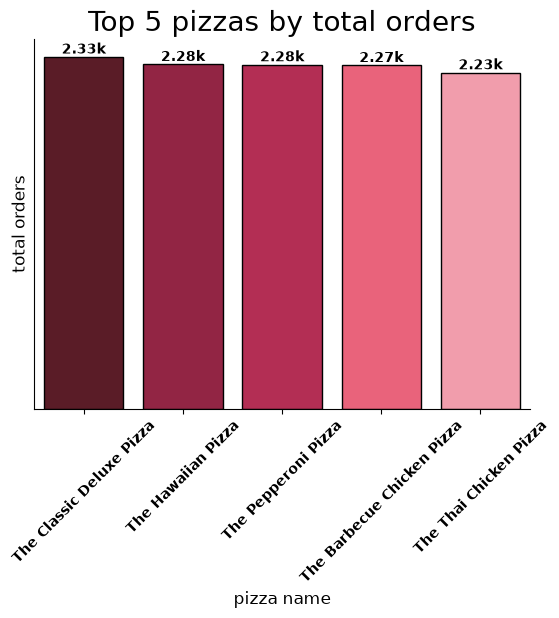

In [36]:
#TOP 5 PIZZAS BY TOTAL ORDERS
plt.Figure(figsize=(10,5))
col=['#641220','#a4133c','#c9184a','#ff4d6d','#ff8fa3']
total_order=df.groupby("pizza name")['order id'].nunique().sort_values(ascending=False).nlargest(5).reset_index()
ax=sns.barplot(x='pizza name',y='order id',data=total_order,edgecolor='black',palette=col)
def to_k(x):
    if x>=1000:
        return f'{x/1000:.2f}k'
    else:
        return str(x)
for container in ax.containers:
    labels=[to_k(v) for v in container.datavalues]
    ax.bar_label(container,labels=labels,label_type="edge",fontsize=10,weight='bold')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title("Top 5 pizzas by total orders",fontsize=20)
plt.xlabel("pizza name",fontsize=12)
plt.ylabel("total orders",fontsize=12)
plt.xticks(rotation=45,weight='bold')
plt.yticks([])

C:\Users\NCS B1\AppData\Local\Temp\ipykernel_18864\3438258836.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(x='pizza name',y='order id',data=bott_order,palette=color)


([], [])

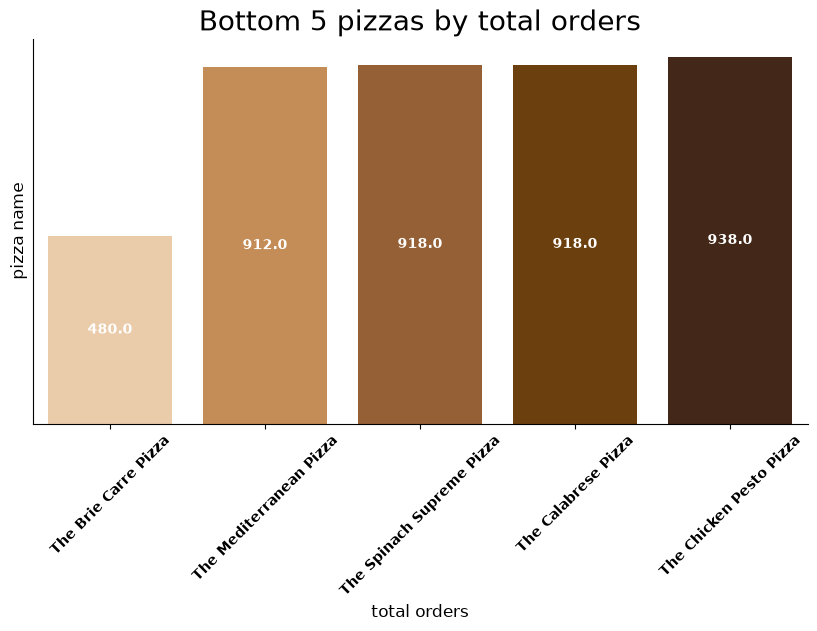

In [37]:
#BOTTOM 5 PIZZAS BY TOTAL ORDERS 
plt.figure(figsize=(10,5))
color=['#f5cca0','#d68c45','#a65e26','#7b3f00','#4a2511']
bott_order=df.groupby("pizza name")['order id'].nunique().sort_values(ascending=True).nsmallest(5).reset_index()
ax=sns.barplot(x='pizza name',y='order id',data=bott_order,palette=color)
def to_k(value):
    if value>=1000:
        return f'{value/1000:.2f}k'
    else:
        return str(value)
for container in ax.containers:
    labels=[to_k(v) for v in container.datavalues]
    ax.bar_label(container,labels=labels,label_type="center",fontsize=10,color='white',weight='bold')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title("Bottom 5 pizzas by total orders",fontsize=20)
plt.xlabel("total orders",fontsize=12)
plt.ylabel("pizza name",fontsize=12)
plt.xticks(rotation=45,weight='bold')
plt.yticks([])

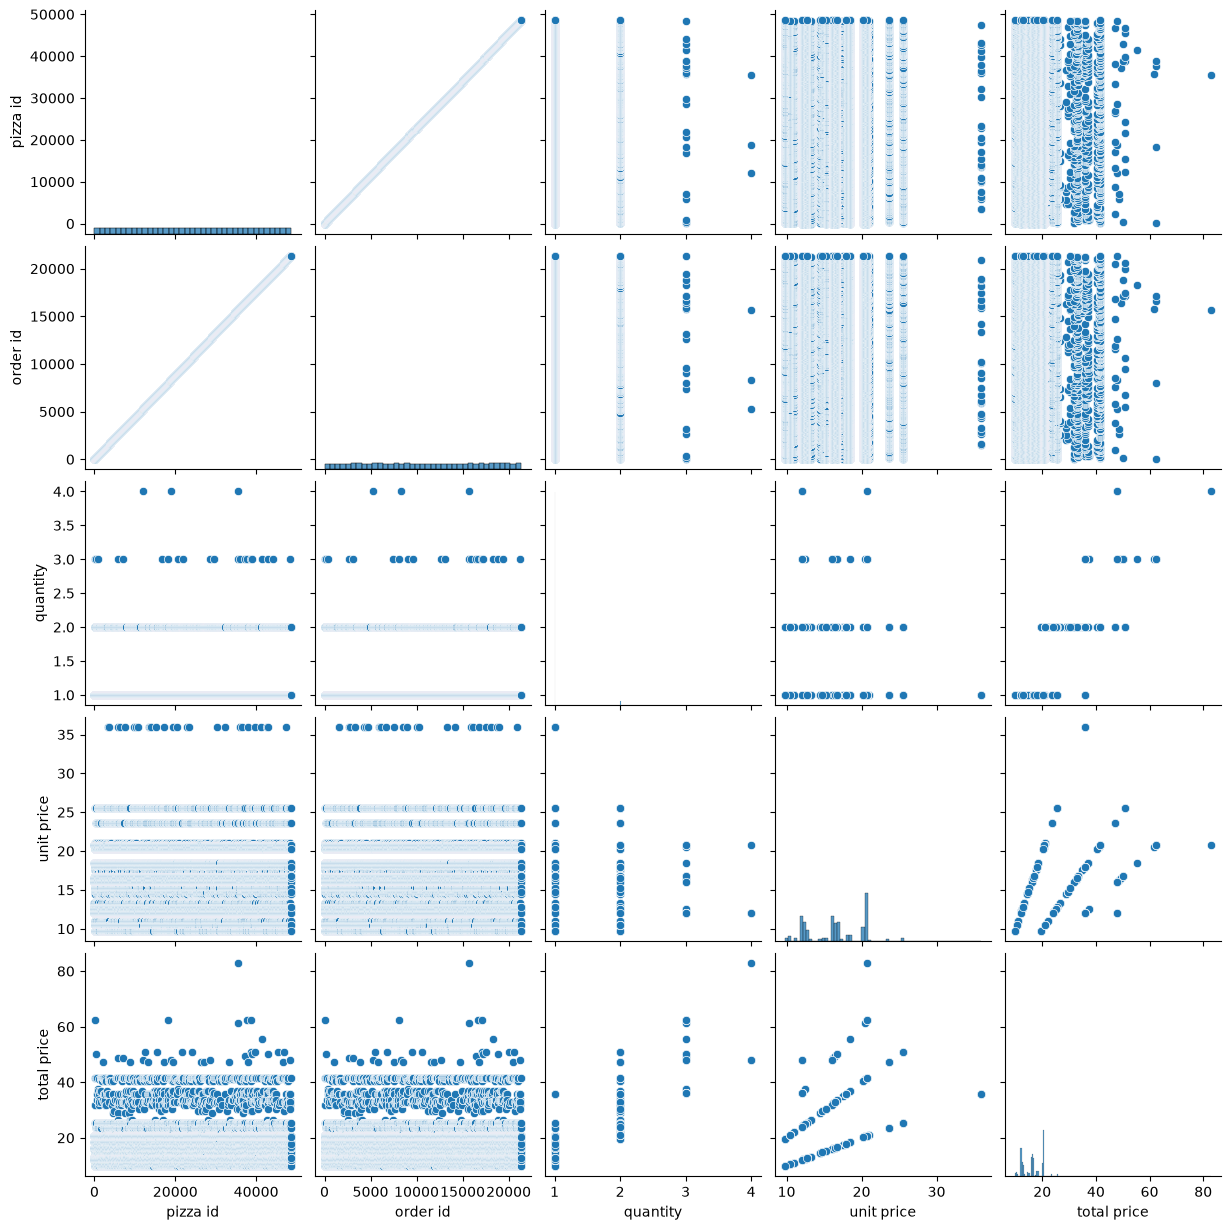

In [38]:
sns.pairplot(df)